# Model comparison: every model family on the same folds
**Question:** which model should we submit? Over the project we built logistic regression, random forests, LightGBM,
XGBoost, an in-context kNN (a TabPFN-like model) and CatBoost, plus rank-average blends of them, each in its own notebook.
This notebook replaces those: it runs **all of them on the identical 5 folds** with the same features, so the comparison is fair.

| Candidate | What it is |
|---|---|
| `logistic` | L2 logistic regression, 8 lean features + one-hot categoricals, C = 0.3, unweighted (the explainable baseline) |
| `random_forest` | 600 bagged trees, leaves of ≥ 25 rows |
| `lightgbm` | 4 leaves, ≥ 150 rows per leaf (tuned by a 70-config random search) |
| `xgboost` | depth 3, native categoricals, unweighted |
| `knn` | in-context kNN: smoothed fraud share of the 150 nearest training rows |
| `catboost` | depth 4, lr 0.03 × 800, L2 10, averaged over seeds (the final spec) |
| blends | rank averages: CatBoost + logistic, CatBoost + LightGBM + logistic, CatBoost + RF, CatBoost + kNN |

**Selection rule, fixed before looking at the results:**
1. rank by out-of-fold PR-AUC;
2. shortlist everything *statistically tied* with the leader (the paired bootstrap 95% interval of the difference contains 0);
3. among the shortlist, prefer the best score on **unseen data** (the public leaderboard, `results/leaderboard.csv`);
4. otherwise the simplest candidate.

The code lives in the `fraudlab` package (`fraudlab/models.py`, `fraudlab/select.py`); this notebook runs it and shows the results.
About 3 minutes on a laptop CPU.

In [1]:
import sys, json
sys.path.insert(0, "..")                       # the repo root, where the fraudlab package lives
import pandas as pd
from IPython.display import Image, Markdown, display
from fraudlab import select, config as C

selection = select.run()

  10 candidates from 6 base learners, 5-fold CV


  logistic       OOF PR-AUC 0.2280   (  2.7s)


  random_forest  OOF PR-AUC 0.2070   ( 38.6s)


  lightgbm       OOF PR-AUC 0.2168   (  3.0s)


  xgboost        OOF PR-AUC 0.2012   (  3.1s)


  knn            OOF PR-AUC 0.1794   (  4.4s)


  catboost       OOF PR-AUC 0.2384   ( 43.6s)


  figure -> docs/figures/model_selection.png


  figure -> docs/figures/alert_dial.png
                              PR-AUC  CI low  CI high  top-100 precision      F1  recall  public PR-AUC  tied with CV leader
candidate                                                                                                                   
catboost+logistic 50/50       0.2392  0.1938   0.2845               0.63  0.2944  0.2890         0.1832                 True
catboost                      0.2384  0.1932   0.2852               0.61  0.3045  0.2946         0.1959                 True
catboost+random_forest 60/40  0.2373  0.1934   0.2822               0.61  0.3033  0.2720            NaN                 True
catboost+lightgbm+logistic    0.2361  0.1906   0.2808               0.61  0.2886  0.2833            NaN                 True
catboost+knn 70/30            0.2284  0.1839   0.2751               0.61  0.3018  0.2663            NaN                False
logistic                      0.2280  0.1839   0.2733               0.60  0.2897  0.2

## Results
PR-AUC with a 95% bootstrap interval; F1 / recall at each candidate's best alert share; the public score where the candidate was uploaded.

In [2]:
table = pd.read_csv(C.SELECTION_DIR / "leaderboard.csv", index_col=0)
cols = ["family", "PR-AUC", "CI low", "CI high", "delta vs leader", "tied with CV leader", "top-100 precision", "F1", "recall", "public PR-AUC"]
display(table[cols].round(4))
print(json.dumps(selection, indent=2))

,family,PR-AUC,CI low,CI high,delta vs leader,tied with CV leader,top-100 precision,F1,recall,public PR-AUC
candidate,,,,,,,,,,
catboost+logistic 50/50,boosted trees + linear,0.2392,0.1938,0.2845,0.0000,True,0.63,0.2944,0.2890,0.1832
catboost,boosted trees,0.2384,0.1932,0.2852,-0.0008,True,0.61,0.3045,0.2946,0.1959
catboost+random_forest 60/40,boosted trees + bagged trees,0.2373,0.1934,0.2822,-0.0019,True,0.61,0.3033,0.2720,NaN
catboost+lightgbm+logistic,boosted trees + boosted trees + linear,0.2361,0.1906,0.2808,-0.0031,True,0.61,0.2886,0.2833,NaN
catboost+knn 70/30,boosted trees + instance-based,0.2284,0.1839,0.2751,-0.0107,False,0.61,0.3018,0.2663,NaN
logistic,linear,0.2280,0.1839,0.2733,-0.0112,True,0.60,0.2897,0.2351,NaN
lightgbm,boosted trees,0.2168,0.1711,0.2637,-0.0223,False,0.57,0.2830,0.2096,0.1901
random_forest,bagged trees,0.2070,0.1648,0.2552,-0.0322,False,0.55,0.2916,0.2408,NaN
xgboost,boosted trees,0.2012,0.1575,0.2471,-0.0380,False,0.57,0.2692,0.1841,NaN


{
  "selected": "catboost",
  "reason": "highest public PR-AUC among the candidates tied on CV",
  "cv_leader": "catboost+logistic 50/50",
  "shortlist": [
    "catboost+logistic 50/50",
    "catboost",
    "catboost+random_forest 60/40",
    "catboost+lightgbm+logistic",
    "logistic"
  ],
  "flag_share": 0.0165,
  "cv_pr_auc": 0.23841780021272457,
  "public_pr_auc": 0.19586
}


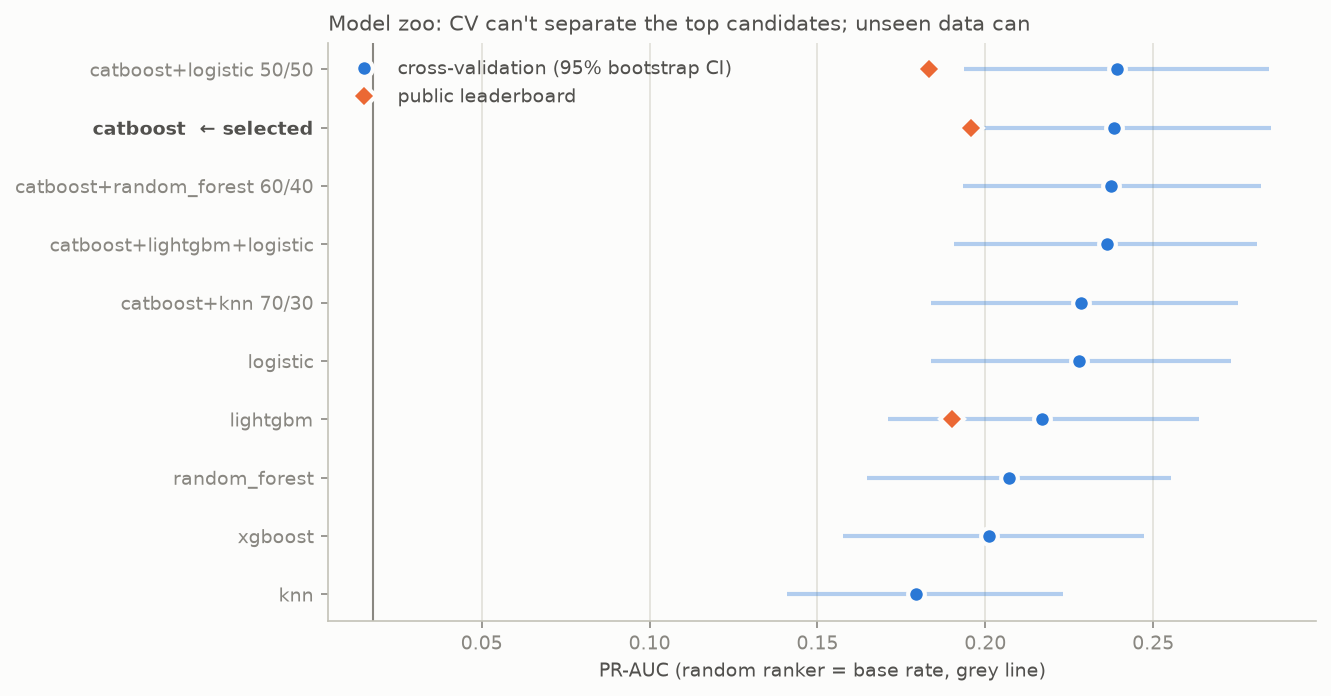

In [3]:
display(Image(str(C.FIGURES_DIR / "model_selection.png")))

## What this shows
- **CatBoost is the strongest single model** on CV, about 0.01 above logistic regression and 0.02 above LightGBM.
- **CV can't separate CatBoost from its blends:** the top candidates' intervals overlap almost completely, and the
  CatBoost + logistic blend even edges ahead on CV.
- **Unseen data can.** On the public test set, which is shifted, the blend scored **0.183** against CatBoost's **0.196**. Logistic
  regression adds a fixed bonus for each risk flag, and those flags fire far more often in the test set without being fraud. A model
  that learns *combinations* of signals is more robust to that.
- So the rule selects **plain CatBoost**, the same model as `01_final_catboost.ipynb` and the final notebook.

Every model also loses roughly the same ~0.045 from CV to the public test set. The gap is a property of the shifted data, not
of one model; `03_shift_reanchoring.ipynb` tests one explanation for it.

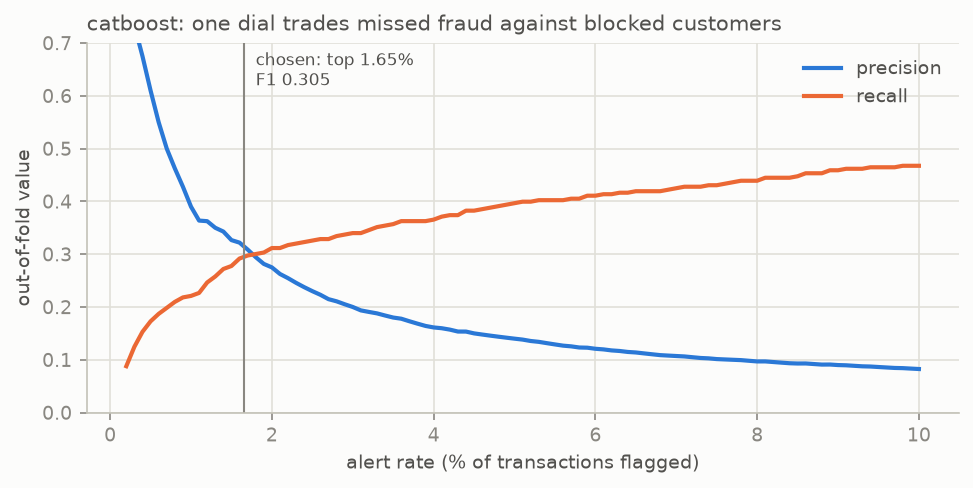

In [4]:
display(Image(str(C.FIGURES_DIR / "alert_dial.png")))

**Operating point.** PR-AUC depends only on the ranking. For F1 and Recall we flag the top 1.65% of transactions,
the out-of-fold F1 optimum. The dial above shows the trade-off a bank can move without retraining.